In [35]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from project_code.backends_library import run_on_local_simulator
from project_code.ansatzes.ansatz_library import custom_linear_cnot
from project_code.hamiltonians.standard_projection_hamiltonian import CustomHamiltonian
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from matplotlib import pyplot as plt

from utils import Utils



In [36]:
n = 2047
p_bits, q_bits = Utils.bits_needed(n)
service, backend = run_on_local_simulator()
hamiltonian = CustomHamiltonian().get_hamiltonian(n, p_bits, q_bits)
ansatz, _ = custom_linear_cnot(p_bits + q_bits - 2)

In [37]:
hamiltonian

SparsePauliOp(['IIIIIIIIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIZIIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIZIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIZIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIZIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIZIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIZIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIZII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIIZI', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIIIZ', 'IIIIIIIIIIIIII', 'ZIIIIIIIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIZIIIIIIII', 'ZIIIIIIIIIIIII', 'ZIIIIZIIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIZIIIIIII', 'ZIIIIIIIIIIIII', 'ZIIIIIZIIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIZIIIIII', 'ZIIIIIIIIIIIII', 'ZIIIIIIZIIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIZIIIII', 'ZIIIIIIIIIIIII', 'ZIIIIIIIZIIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIZIIII', 'ZIIIIIIIIIIIII', 'ZIIIIIIIIZIIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIZIII', 'ZIIIIIIIIIIIII', 'ZIIIIIIIIIZIII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIZII', 'ZIIIIIIIIIIIII', 'ZIIIIIIIIIIZII', 'IIIIIIIIIIIIII', 'IIIIIIIIIIIIZI', 'ZIIIIIIIIIIIII', 'ZIIIIIIIIIII

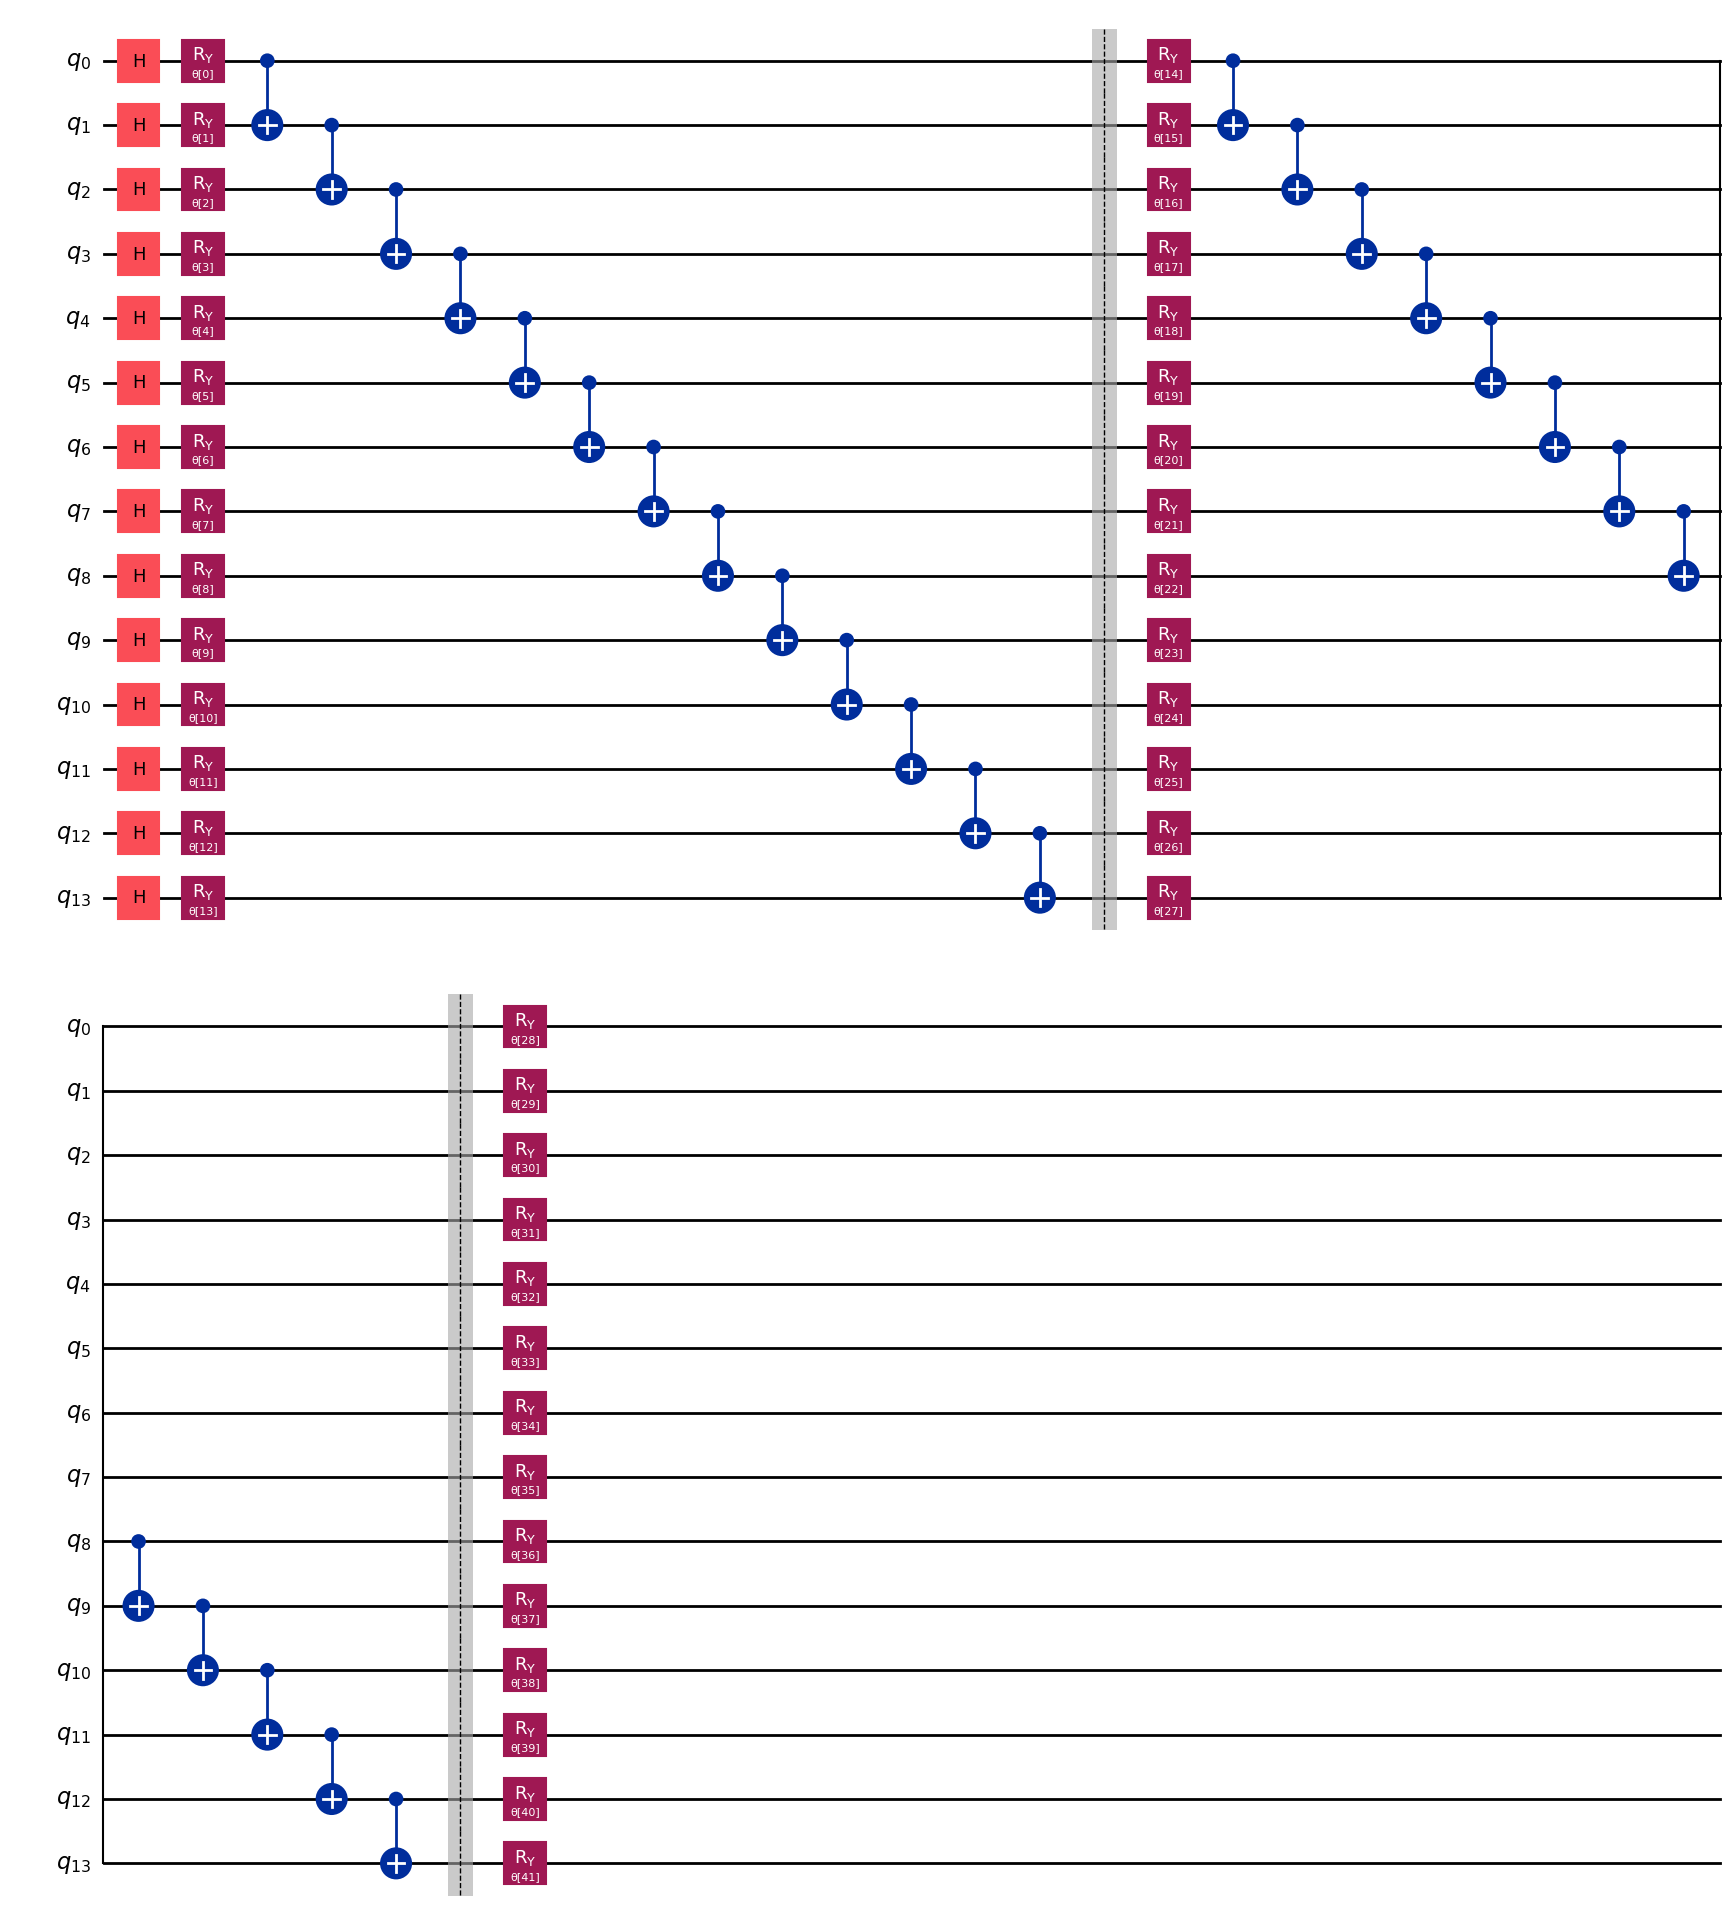

In [38]:
ansatz.draw("mpl")


In [39]:
target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

ansatz_isa = pm.run(ansatz)

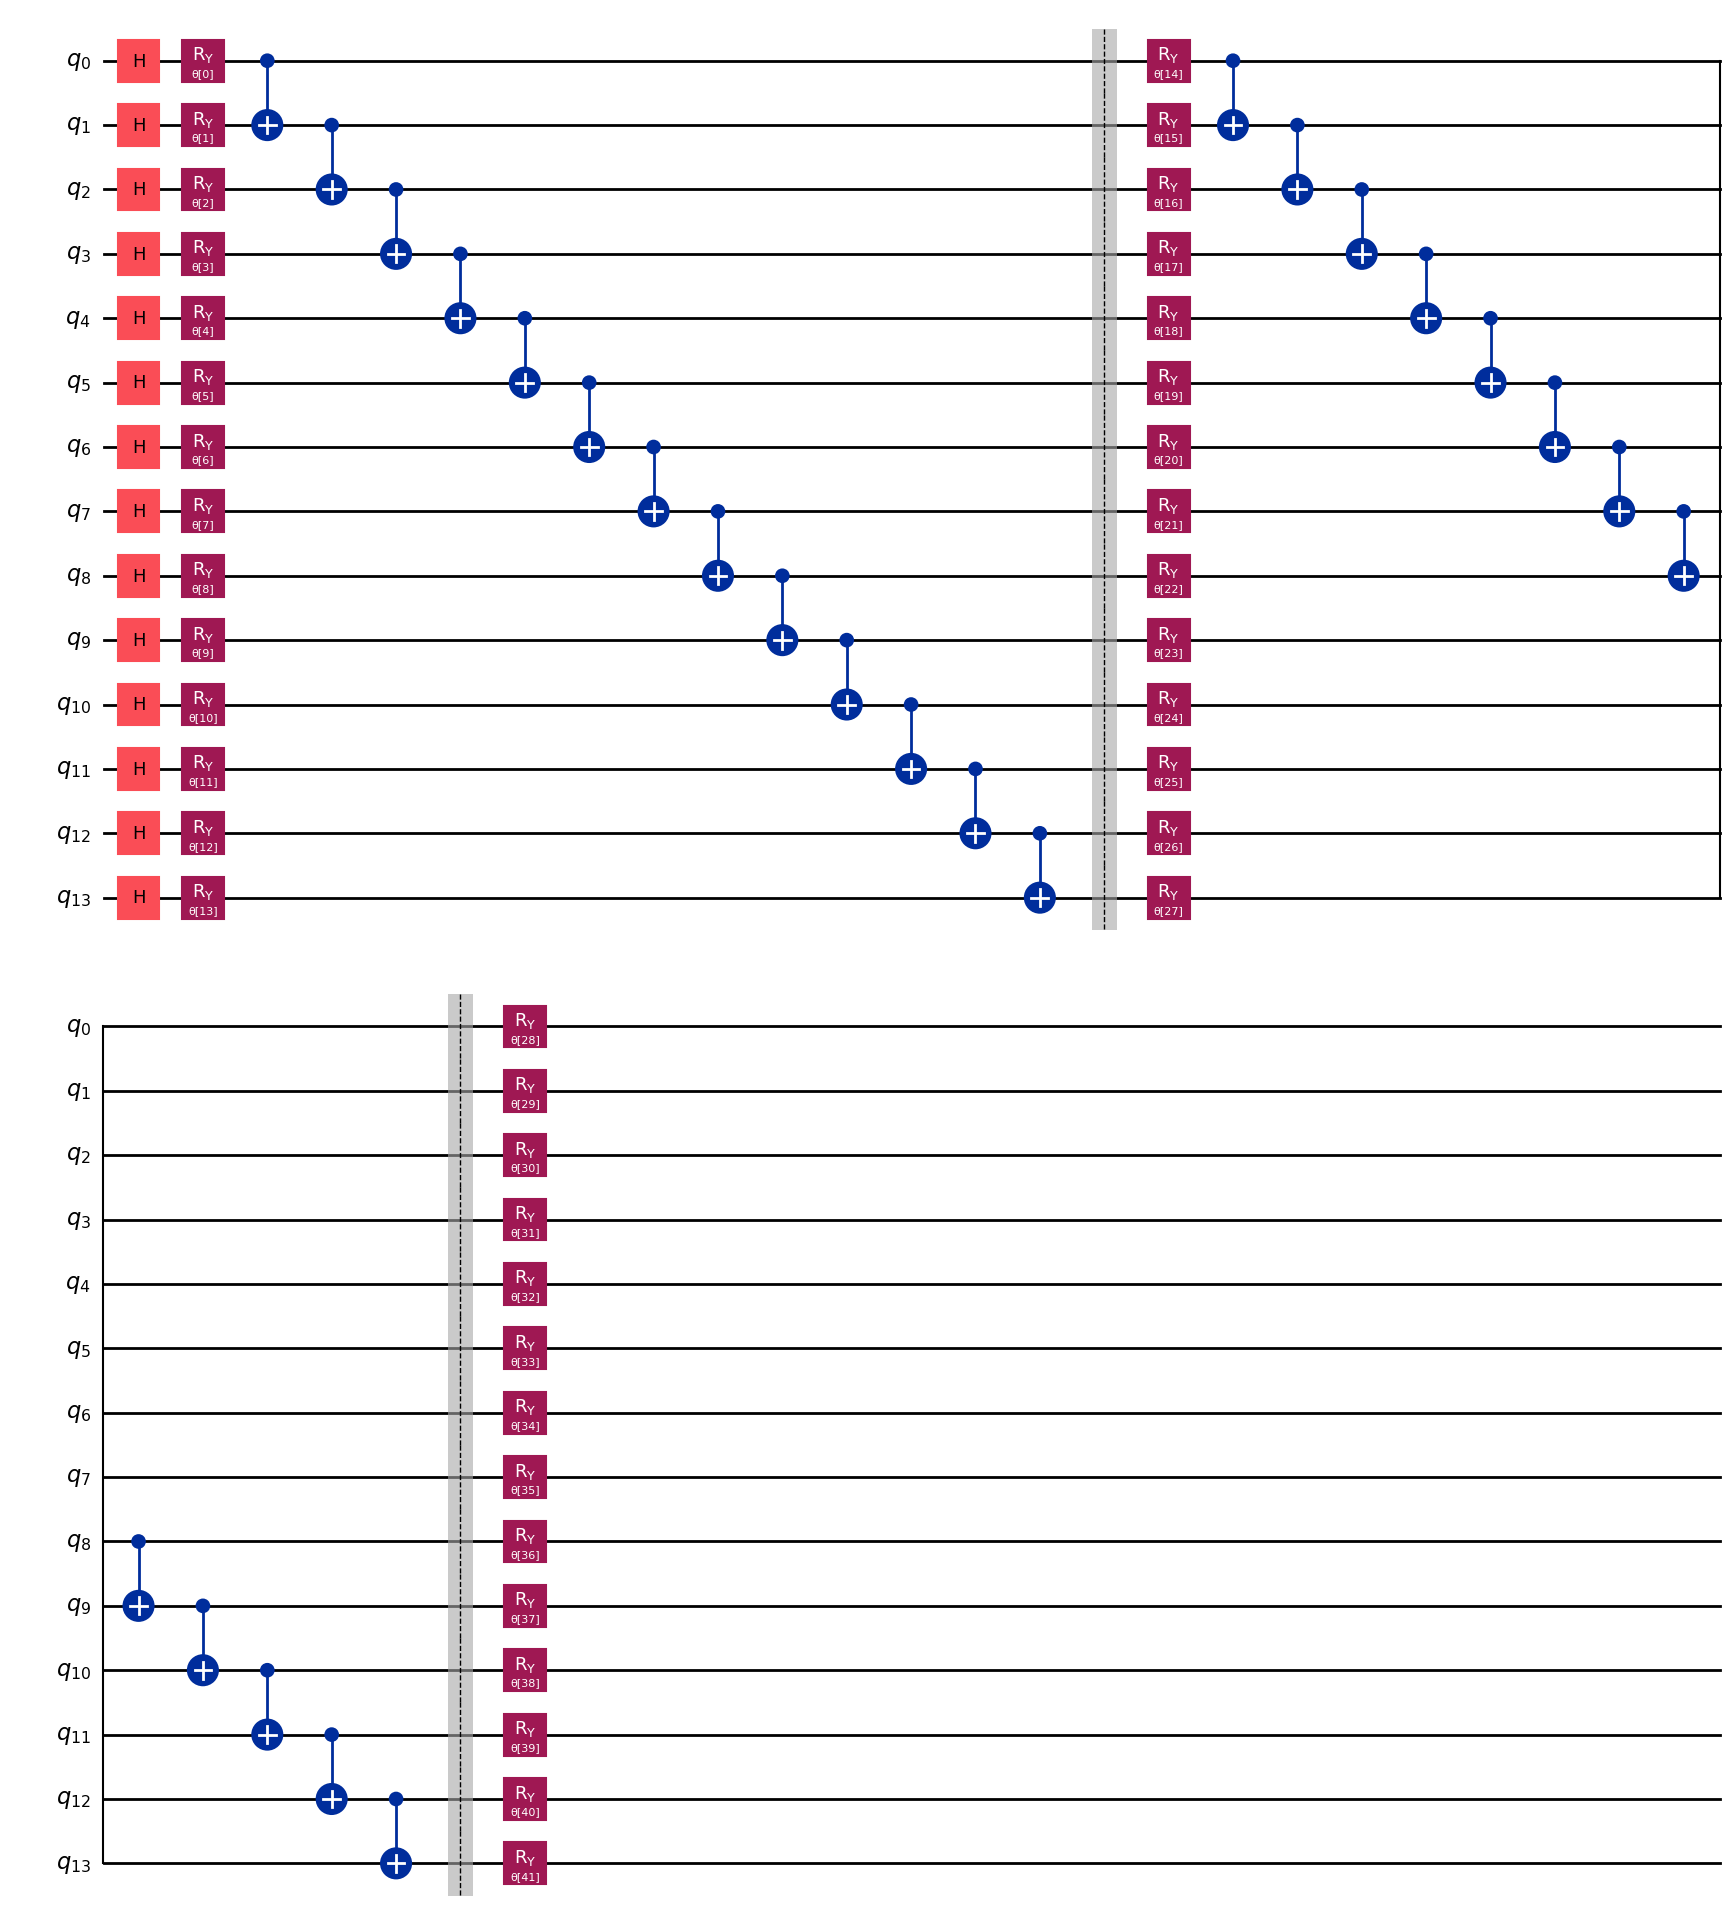

In [40]:
ansatz_isa.draw(output="mpl", idle_wires=False, style="iqp")

In [41]:
hamiltonian_isa = hamiltonian.apply_layout(layout=ansatz_isa.layout)

In [42]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return estimate of energy from estimator

    Parameters:
        params (ndarray): Array of ansatz parameters
        ansatz (QuantumCircuit): Parameterized ansatz circuit
        hamiltonian (SparsePauliOp): Operator representation of Hamiltonian
        estimator (EstimatorV2): Estimator primitive instance
        cost_history_dict: Dictionary for storing intermediate results

    Returns:
        float: Energy estimate
    """
    pub = (ansatz, [hamiltonian], [params])
    result = estimator.run(pubs=[pub]).result()
    energy = result[0].data.evs[0]

    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params
    cost_history_dict["cost_history"].append(energy)
    print(f"Iters. done: {cost_history_dict['iters']} [Current cost: {energy}]")

    return energy

In [43]:
import numpy as np

cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}

x0 = 2 * np.pi * np.random.random(ansatz.num_parameters)


In [44]:

from qiskit_ibm_runtime import Session
from scipy.optimize import minimize

with Session(backend=backend) as session:
    estimator = Estimator(mode=session)
    estimator.options.default_shots = 10000

    res = minimize(
        cost_func,
        x0,
        args=(ansatz_isa, hamiltonian_isa, estimator),
        method="cobyla",
    )

Iters. done: 1 [Current cost: 198827777.1856004]
Iters. done: 2 [Current cost: 245790356.2892002]
Iters. done: 3 [Current cost: 178907864.56760064]
Iters. done: 4 [Current cost: 230142607.57080004]
Iters. done: 5 [Current cost: 170667434.05359986]
Iters. done: 6 [Current cost: 163014303.79200003]
Iters. done: 7 [Current cost: 165941007.01360047]
Iters. done: 8 [Current cost: 162883736.59519973]
Iters. done: 9 [Current cost: 160393422.04119974]
Iters. done: 10 [Current cost: 163668509.9476001]
Iters. done: 11 [Current cost: 190484837.47119957]
Iters. done: 12 [Current cost: 115236805.62479995]
Iters. done: 13 [Current cost: 99026507.35319993]
Iters. done: 14 [Current cost: 106764498.14199995]
Iters. done: 15 [Current cost: 98066767.85160007]
Iters. done: 16 [Current cost: 37151160.495199844]
Iters. done: 17 [Current cost: 31299049.056399897]
Iters. done: 18 [Current cost: 21502796.212000046]
Iters. done: 19 [Current cost: 18591320.011599954]
Iters. done: 20 [Current cost: 21836043.68399

In [45]:
res

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: 2670282.207600141
       x: [ 8.724e-01  3.029e+00 ...  3.333e+00  2.935e+00]
    nfev: 482
   maxcv: 0.0

In [46]:
cost_history_dict["prev_vector"] == res.x

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [47]:
cost_history_dict["iters"] == res.nfev

True

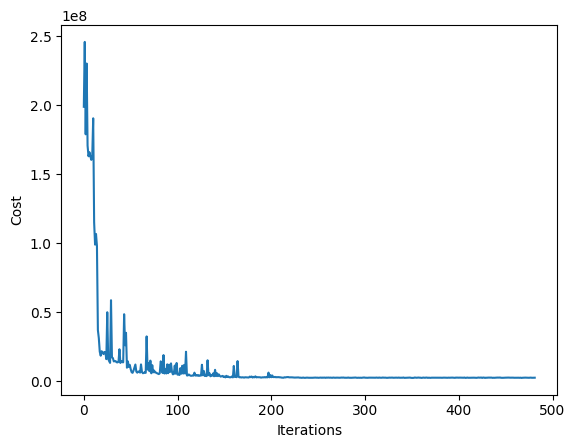

In [48]:
fig, ax = plt.subplots()
ax.plot(range(cost_history_dict["iters"]), cost_history_dict["cost_history"])
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost")
plt.draw()

# Post Process For Factors

In [49]:
optimal_params = res.x
optimal_params

array([0.87243541, 3.02945211, 2.82641687, 5.63482032, 1.55722639,
       0.17885491, 1.45094949, 2.62670661, 4.32381512, 3.06947591,
       5.07322241, 3.32229877, 5.84671219, 2.94589653, 2.40945782,
       4.38000278, 6.12024968, 4.66420402, 1.94734749, 3.48269671,
       1.98606231, 5.82428787, 0.72733894, 6.74701486, 0.37441459,
       5.86785244, 4.90280014, 7.18128556, 6.20829182, 6.09072602,
       0.129552  , 4.23836895, 0.42871921, 2.77802051, 0.77598765,
       0.70787871, 1.05356352, 4.76986587, 4.82186741, 3.67717242,
       3.33274326, 2.93533629])

In [50]:
# 1. Bind parameters to the ansatz
bound_circuit = ansatz.assign_parameters(optimal_params)

# 2. Add measurement if not already added
bound_circuit.measure_all()

# 3. Transpile the circuit for the Aer simulator
simulator = AerSimulator()
compiled_circuit = transpile(bound_circuit, simulator)

# 4. Run the circuit
job = simulator.run(compiled_circuit, shots=10000)
result = job.result()

# 5. Get the measurement counts
statistics = result.get_counts()
# most_likely_bitstring = max(statistics, key=statistics.get)

# print("Most likely bitstring:", most_likely_bitstring)

In [51]:
for key in result.get_counts().keys():
    p, q = (int(key[:p_bits - 1], 2) << 1) + 1, (int(key[p_bits - 1:], 2) << 1) + 1
    if p * q == n:
        print("found: ", p, q)